In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Show one value per region on the Swanson map

How to cite this: see [Citations](../citations.qmd).

The Swanson flatmap is a 2D representation of the mouse brain to facilitate comparative analysis of brain data.
We extended the mouse atlas presented by [Hahn et al.](https://onlinelibrary.wiley.com/doi/full/10.1002/cne.24966?casa_token=kRb4fuUae6wAAAAA%3AHoiNx1MNVgZNUXT-MZN_mU6LAjKBiz5OE5cFj2Aj-GUE9l-oBllFUaM11XwCtEbpJyxKrwaMRnXC7MjY)
to interface programmatically with the Allen Atlas regions.

<Axes: >

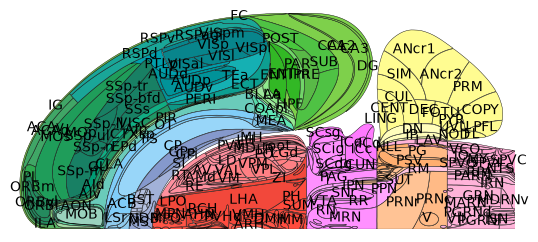

In [2]:
import numpy as np
from iblatlas.plots import plot_swanson_vector
from iblatlas.atlas import BrainRegions

br = BrainRegions()

# Plot Swanson map will default colors and acronyms
plot_swanson_vector(br=br, annotate=True)

For which regions the Swanson map can show, and how to convert a region list to them, see [Make a region list plottable on the Swanson map](make-regions-plottable-on-swanson.ipynb).

## Plotting values on the swanson flatmap
### Single hemisphere display
Provide an array of brain region acronyms and an array of corresponding values.

<Axes: >

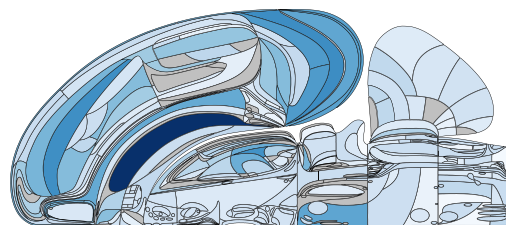

In [3]:
# prepare array of acronyms
acronyms = np.array(
    ['VPLpc', 'PO', 'LP', 'DG', 'CA1', 'PTLp', 'MRN', 'APN', 'POL',
       'VISam', 'MY', 'PGRNl', 'IRN', 'PARN', 'SPVI', 'NTS', 'SPIV',
       'NOD', 'IP', 'AON', 'ORBl', 'AId', 'MOs', 'GRN', 'P', 'CENT',
       'CUL', 'COApm', 'PA', 'CA2', 'CA3', 'HY', 'ZI', 'MGv', 'LGd',
       'LHA', 'SF', 'TRS', 'PVT', 'LSc', 'ACAv', 'ACAd', 'MDRNv', 'MDRNd',
       'COPY', 'PRM', 'DCO', 'DN', 'SIM', 'MEA', 'SI', 'RT', 'MOp', 'PCG',
       'ICd', 'CS', 'PAG', 'SCdg', 'SCiw', 'VCO', 'ANcr1', 'ENTm', 'ENTl',
       'NOT', 'VPM', 'VAL', 'VPL', 'CP', 'SSp-ul', 'MV', 'VISl', 'LGv',
       'SSp-bfd', 'ANcr2', 'DEC', 'LD', 'SSp-ll', 'V', 'SUT', 'PB', 'CUN',
       'ICc', 'PAA', 'EPv', 'BLAa', 'CEAl', 'GPe', 'PPN', 'SCig', 'SCop',
       'SCsg', 'RSPd', 'RSPagl', 'VISp', 'HPF', 'MGm', 'SGN', 'TTd', 'DP',
       'ILA', 'PL', 'RSPv', 'SSp-n', 'ORBm', 'ORBvl', 'PRNc', 'ACB',
       'SPFp', 'VM', 'SUV', 'OT', 'MA', 'BST', 'LSv', 'LSr', 'UVU',
       'SSp-m', 'LA', 'CM', 'MD', 'SMT', 'PFL', 'MARN', 'PRE', 'POST',
       'PRNr', 'SSp-tr', 'PIR', 'CTXsp', 'RN', 'PSV', 'SUB', 'LDT', 'PAR',
       'SPVO', 'TR', 'VISpm', 'MS', 'COApl', 'BMAp', 'AMd', 'ICe', 'TEa',
       'MOB', 'SNr', 'GU', 'VISC', 'SSs', 'AIp', 'NPC', 'BLAp', 'SPVC',
       'PYR', 'AV', 'EPd', 'NLL', 'AIv', 'CLA', 'AAA', 'AUDv', 'TRN'],
      dtype='<U8')
values = np.array([ 7.76948616, 25.51506047, 21.31094194, 23.11353701, 26.18071135,
       16.42116195, 22.4522099 , 20.04564731,  9.98702368, 11.00518771,
       11.23163309,  3.90841049, 11.44982496,  7.49984019, 10.59146742,
        7.68845853, 10.38817938,  6.53187499, 14.22331705, 19.26731921,
       14.6739601 , 10.37711987, 19.87087356, 12.56497513, 11.03204901,
       12.85149192, 10.39367399,  5.26234078,  7.36780286,  7.77672633,
       22.30843636,  9.63356153, 11.33369508,  7.70210975, 14.56984632,
        7.95488849,  9.85956065, 10.40381726,  6.31529234,  7.82651245,
       11.3339313 , 12.26268021,  8.67874273,  8.07579753, 10.14307203,
       10.08081832,  7.88595354,  7.49586605, 12.6491355 ,  7.92629876,
       12.52110187, 14.27405322, 25.95808524,  6.52603939,  3.15160563,
       11.60061018, 11.1043498 ,  8.0733422 , 11.71522066,  4.62765218,
        7.49833868, 18.78977643, 17.00685931,  6.3841865 , 21.0516987 ,
       13.16635271, 13.32514284, 39.00407907, 10.17439742, 10.71338756,
       12.98324876,  9.36698057, 18.72583288,  8.86341551,  8.59402471,
       14.40309408, 11.2151223 ,  8.54318159,  7.27041139,  7.54384726,
        7.12004486,  8.61247715,  6.24836557,  7.61490273,  7.97743213,
        5.90638179, 11.18067752,  9.60402511, 10.27972062,  4.88568098,
        5.15238733,  9.48240265,  5.5200633 , 17.34425384, 20.51738915,
        8.67575586, 10.13415575, 12.55792577, 11.28995505, 12.01846393,
       16.44519718, 11.55540348, 12.6760064 , 14.59124425, 16.08650743,
        5.49252396, 14.21853759,  9.80928243, 11.1998899 ,  8.53843453,
        8.95692822,  7.44622149,  9.41208445, 10.00368097, 18.36862111,
        5.90905433, 18.73273459, 10.41462726, 10.38639344, 13.71164211,
        8.1023596 ,  7.57087137,  3.95315742, 12.24423806, 10.4316517 ,
       10.75912468,  9.21246988, 21.71756051,  8.55320981, 10.69256597,
        8.20796144, 24.13594074,  4.55095547, 12.43055174,  7.00374928,
        4.72499044,  6.22081559,  6.50700078,  6.73499461, 12.77964412,
        8.8475468 , 11.20443401,  6.59475644,  8.59815892,  7.16696761,
       10.62813483,  7.77992602, 16.02889234,  9.21649532,  7.08618021,
        5.56980282,  3.61976479,  6.86178595, 13.44050831, 11.9525432 ,
        7.21974504,  6.28513041,  6.8381433 ,  5.93095918,  8.12844537,
        8.62486916])


# and display on a single hemishphere, using a blue colormap
plot_swanson_vector(acronyms, values, cmap='Blues', br=br)

### Lateralized display
A more advanced example is when each hemisphere is assigned a different value. For this, you need to convert the acronyms to Allen ID, and assign positive/negative ID values to differentiate between the two hemispheres.

<Axes: >

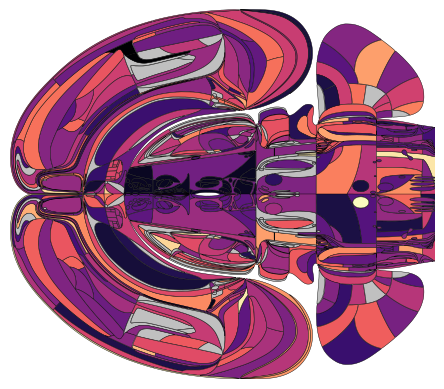

In [4]:
# In our atlas convention, differentiating between hemishperes is done using negative indices
regions_rl = np.r_[br.acronym2id(acronyms), -br.acronym2id(acronyms)]
# assign random values for the sake of this example
values_rl = np.random.randn(regions_rl.size)
# display with an explicit dual hemisphere setup
plot_swanson_vector(regions_rl, values_rl, hemisphere='both', cmap='magma', br=br)

## Portrait orientation
One can also mirror the hemispheres and orient the display in portrait mode.

<Axes: >

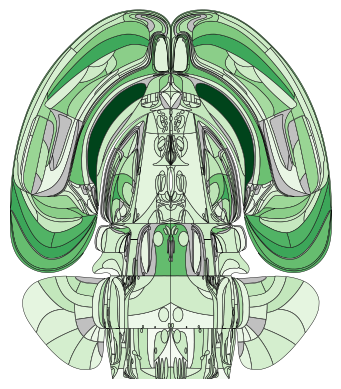

In [5]:
plot_swanson_vector(acronyms=acronyms, values=values, orientation='portrait', cmap='Greens', hemisphere='mirror')